# DL_01 — Dataset Audit, Raster Preparation and Leakage-Safe Splitting

**Owner: Suhaani Garg**  
**Work package 1 of 5 — the main data-engineering component**

## Objective

Prepare the complete 224-case UrbanTALES idealized dataset for spatial deep learning. This notebook audits the full Phase 2 ZIP, joins the official geometry and simulation metadata, reads pedestrian-level velocity components, aligns the topology and CFD grids, creates a valid-air mask, preserves the original spatial resolution, and creates a family-held-out train/validation/test split.

The notebook writes all runtime products into the repository-root `dl_results/` folder. It does not rely on precomputed Phase 2 metrics, plots, model weights or predictions.

## Dataset facts that affect the implementation

- The complete Phase 2 archive contains 224 pedestrian NetCDF files, 224 topology grids, 224 time-series NetCDF files and 224 profile CSV files.
- The idealized subset has 112 layouts, 16 plan families and two wind directions (0° and 45°).
- The spatial arrays do **not** all have the same dimensions. The audit found multiple native grid shapes, so we must not silently resize or crop them to one arbitrary image size.
- NetCDF arrays are stored in `(x, y)` order. The model uses `(y, x)` order, so the code transposes every aligned spatial array together.
- The topography grid uses zero for open cells and positive values for building heights. The loss mask keeps only cells with zero topography and finite values in both velocity components.
- The inspected `uped` and `vped` variables do not expose `units` attributes. The pipeline therefore preserves their stored values and does not label their errors as m/s without a verified source definition.

## Required files

Place the complete reassembled Phase 2 archive in `data/raw/` and name it `selected_files (4).zip`. The Phase 1 repository must already contain `metadata_ideal.json`, `metadata.csv` and `UrbanTALES-flowdata.csv` in `data/raw/`.

The Phase 1 sample NetCDF archive is not a substitute for the complete Phase 2 archive.

## 1. Environment and repository paths

Run this notebook from the existing T006 repository. If you are using Colab, clone the repository first, add the `Deep Learning Pipeline` and `dl_src` folders at its root, and place the full Phase 2 ZIP in `data/raw/`.

In [1]:
from pathlib import Path
import sys
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

# Locate the existing repository before importing the shared Phase 2 package.
current = Path.cwd().resolve()
candidates = [current, *current.parents]
ROOT = None
for candidate in candidates:
    if (candidate / "data" / "raw").is_dir() and (candidate / "Machine Learning Pipeline").is_dir():
        ROOT = candidate
        break
    if candidate.is_dir():
        for child in candidate.iterdir():
            if child.is_dir() and (child / "data" / "raw").is_dir() and (child / "Machine Learning Pipeline").is_dir():
                ROOT = child
                break
    if ROOT is not None:
        break
if ROOT is None:
    raise FileNotFoundError("Clone/open the existing T006 repository first; the Phase 2 folder must be added at its root.")

sys.path.insert(0, str(ROOT))
from dl_src.paths import get_project_paths
PATHS = get_project_paths(ROOT)
DL_RESULTS = PATHS["dl_results"]
FIELDS_DIR = PATHS["fields"]
FIGURES_DIR = PATHS["figures"]
MODELS_DIR = PATHS["models"]
PREDICTIONS_DIR = PATHS["predictions"]

print("Repository root:", ROOT)
print("Runtime outputs:", DL_RESULTS)


Repository root: /Users/suhaanigarg/Desktop/T006-urban-microclimate-modelling
Runtime outputs: /Users/suhaanigarg/Desktop/T006-urban-microclimate-modelling/dl_results


In [2]:
# Check the required input files before reading the large archive.
required_metadata_files = [
    PATHS["raw"] / "metadata_ideal.json",
    PATHS["raw"] / "metadata.csv",
    PATHS["raw"] / "UrbanTALES-flowdata.csv",
]
missing_metadata_files = [path for path in required_metadata_files if not path.exists()]
if missing_metadata_files:
    raise FileNotFoundError(
        "Missing Phase 1 raw metadata files:\n" + "\n".join(str(path) for path in missing_metadata_files)
    )

PHASE2_ARCHIVE = PATHS["archive"]
if PHASE2_ARCHIVE is None:
    raise FileNotFoundError(
        "The complete Phase 2 archive was not found. Copy the reassembled 990 MiB archive "
        "to data/raw/selected_files (4).zip. Do not use the small Phase 1 sample NetCDF ZIP."
    )

print("Phase 2 archive:", PHASE2_ARCHIVE)
print("Archive size (MiB):", round(PHASE2_ARCHIVE.stat().st_size / (1024 ** 2), 2))

Phase 2 archive: /Users/suhaanigarg/Desktop/T006-urban-microclimate-modelling/data/raw/selected_files (4).zip
Archive size (MiB): 990.0


In [3]:
%pip install torch


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python3.13 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## 2. Build the case-level metadata table

Each simulation ID has a direction-specific suffix. Removing `_d00` or `_d45` gives its `layout_id`. The Phase 1 grouping rule derives `family_id` from the arrangement/density code. Family and layout IDs are used only for grouping and traceability; they are never supplied as model input channels.

The friction velocity `u_tau` is retained as a simulation-condition input. The pedestrian scalar `pedU` is retained only for a diagnostic cross-check and is not used as a target or predictor.

In [4]:
from dl_src.data import build_case_manifest, make_grouped_split

manifest = build_case_manifest(
    PATHS["raw"] / "metadata_ideal.json",
    PATHS["raw"] / "metadata.csv",
    PATHS["raw"] / "UrbanTALES-flowdata.csv",
)

print("Cases:", len(manifest))
print("Layouts:", manifest["layout_id"].nunique())
print("Families:", manifest["family_id"].nunique())
print("Wind directions:", sorted(manifest["wind_direction_deg"].unique()))
display(manifest.head())

manifest.to_csv(DL_RESULTS / "dl_case_metadata_manifest.csv", index=False)

Cases: 224
Layouts: 112
Families: 16
Wind directions: [np.float64(0.0), np.float64(45.0)]


,simulation_id,layout_id,family_id,wind_direction_deg,wind_direction_sin,wind_direction_cos,u_tau_m_s,dxdy_m,plan_area_density,configuration,horizontal_configuration,height_mean_m,height_std_m,height_min_m,height_max_m,building_count,domain_size_catalogue,pedU_catalogue_m_s_diagnostic_only
0,UA0625_d00,UA0625,A0625,0.0,0.000000,1.000000,0.210141,0.5,0.062500,idealized-uniform_d00,Aligned,16.0,0.0,16.0,16.0,15,320m x 192m,3.932918
1,UA0625_d45,UA0625,A0625,45.0,0.707107,0.707107,0.210141,0.5,0.062500,idealized-uniform_d45,Aligned,16.0,0.0,16.0,16.0,15,320m x 192m,2.797551
2,UA1111_d00,UA1111,A1111,0.0,0.000000,1.000000,0.209432,0.5,0.111111,idealized-uniform_d00,Aligned,16.0,0.0,16.0,16.0,15,240m x 144m,2.757612
3,UA1111_d45,UA1111,A1111,45.0,0.707107,0.707107,0.209432,0.5,0.111111,idealized-uniform_d45,Aligned,16.0,0.0,16.0,16.0,15,240m x 144m,2.115069
4,UA16_d00,UA16,A16,0.0,0.000000,1.000000,0.208715,0.5,0.160000,idealized-uniform_d00,Aligned,16.0,0.0,16.0,16.0,15,200m x 120m,2.188381


## 3. Audit and prepare every spatial case

The next cell reads the ZIP directly. It does not extract the original 990 MiB archive to a second full-size folder. For each case it:

1. locates the matching `*_ped.nc` and `_topo` members;
2. reads `uped`, `vped`, `x` and `y` from the NetCDF4/HDF5 file;
3. reads the numeric topography grid;
4. checks that the velocity and topography dimensions match;
5. creates the valid-air mask;
6. transposes the arrays together from `(x, y)` to `(y, x)`;
7. stores a compressed per-case `.npz` file under `dl_results/processed_fields/`.

No interpolation or resampling is performed. The varying native dimensions are preserved.

In [5]:
from dl_src.data import prepare_phase2_dataset

# This is the main data-preparation run. It processes all 224 cases.
data_audit, dataset_summary = prepare_phase2_dataset(
    archive_path=PHASE2_ARCHIVE,
    manifest=manifest,
    fields_dir=FIELDS_DIR,
    results_dir=DL_RESULTS,
)

display(data_audit.head())
print(json.dumps(dataset_summary, indent=2))

,simulation_id,pedestrian_netcdf_member,topography_member,time_series_member_verified_not_used,profile_member_verified_not_used,grid_x,grid_y,tensor_height_y,tensor_width_x,valid_air_cells,...,nonfinite_velocity_cells,max_building_height_m,mean_stored_speed_on_valid_cells,pedU_catalogue_m_s_diagnostic_only,dxdy_m,domain_x_length_m,domain_y_length_m,uped_units_attribute,vped_units_attribute,processed_file
0,UA0625_d00,UA0625_d00/UA0625_d00_ped.nc,UA0625_d00/UA0625_d00_topo,UA0625_d00/UA0625_d00_ts.nc,UA0625_d00/profile-UA0625_d00.csv,384,640,640,384,229440,...,16320,16.0,0.796487,3.932918,0.5,192.5,320.5,None,None,dl_results/processed_fields/UA0625_d00.npz
1,UA0625_d45,UA0625_d45/UA0625_d45_ped.nc,UA0625_d45/UA0625_d45_topo,UA0625_d45/UA0625_d45_ts.nc,UA0625_d45/profile-UA0625_d45.csv,384,640,640,384,229440,...,16320,16.0,0.573427,2.797551,0.5,192.5,320.5,None,None,dl_results/processed_fields/UA0625_d45.npz
2,UA1111_d00,UA1111_d00/UA1111_d00_ped.nc,UA1111_d00/UA1111_d00_topo,UA1111_d00/UA1111_d00_ts.nc,UA1111_d00/profile-UA1111_d00.csv,288,480,480,288,121920,...,16320,16.0,0.556974,2.757612,0.5,144.5,240.5,None,None,dl_results/processed_fields/UA1111_d00.npz
3,UA1111_d45,UA1111_d45/UA1111_d45_ped.nc,UA1111_d45/UA1111_d45_topo,UA1111_d45/UA1111_d45_ts.nc,UA1111_d45/profile-UA1111_d45.csv,288,480,480,288,121920,...,16320,16.0,0.436028,2.115069,0.5,144.5,240.5,None,None,dl_results/processed_fields/UA1111_d45.npz
4,UA16_d00,UA16_d00/UA16_d00_ped.nc,UA16_d00/UA16_d00_topo,UA16_d00/UA16_d00_ts.nc,UA16_d00/profile-UA16_d00.csv,240,400,400,240,79680,...,16320,16.0,0.439592,2.188381,0.5,120.5,200.5,None,None,dl_results/processed_fields/UA16_d00.npz


{
  "n_cases": 224,
  "n_layouts": 112,
  "n_families": 16,
  "archive_member_coverage": {
    "pedestrian_netcdf": 224,
    "topography": 224,
    "time_series_netcdf": 224,
    "profile_csv": 224
  },
  "wind_directions_deg": [
    0.0,
    45.0
  ],
  "grid_shapes_xy": [
    "120x200",
    "120x240",
    "132x220",
    "132x264",
    "144x240",
    "144x288",
    "162x270",
    "162x324",
    "192x320",
    "192x384",
    "240x400",
    "240x480",
    "288x480",
    "288x576",
    "384x640",
    "384x768"
  ],
  "min_valid_air_cells": 5184,
  "median_valid_air_cells": 31854.0,
  "max_valid_air_cells": 257472,
  "maximum_building_height_m": 37.0,
  "uped_units_attributes_observed": [
    "None"
  ],
  "vped_units_attributes_observed": [
    "None"
  ],
  "field_units_warning": "The inspected NetCDF variables do not carry units attributes. Raw stored values are retained; do not label field errors as m/s unless the original data documentation confirms the units.",
  "mask_definition": 

## 4. Validate coverage and inspect grid dimensions

A successful run must produce one processed field file for every metadata case. The grid-size table is important: different layouts have different native spatial dimensions. Later, the data loader pads only the bottom and right edges to a multiple of 16 so that the four U-Net downsampling stages work. It crops predictions back to the original size before computing metrics.

In [6]:
assert len(data_audit) == 224
assert data_audit["simulation_id"].nunique() == 224
assert all((FIELDS_DIR / f"{case_id}.npz").exists() for case_id in manifest["simulation_id"])

shape_counts = (
    data_audit.groupby(["grid_x", "grid_y"])
    .size()
    .rename("number_of_cases")
    .reset_index()
    .sort_values(["grid_x", "grid_y"])
)
display(shape_counts)
print("Total prepared files:", len(list(FIELDS_DIR.glob("*.npz"))))
print("Valid air cells — minimum:", int(data_audit["valid_air_cells"].min()))
print("Valid air cells — median:", int(data_audit["valid_air_cells"].median()))
print("Valid air cells — maximum:", int(data_audit["valid_air_cells"].max()))

,grid_x,grid_y,number_of_cases
0,120,200,14
1,120,240,14
2,132,220,14
3,132,264,14
4,144,240,14
5,144,288,14
6,162,270,14
7,162,324,14
8,192,320,14
9,192,384,14


Total prepared files: 224
Valid air cells — minimum: 5184
Valid air cells — median: 31854
Valid air cells — maximum: 257472


## 5. Create the strict grouped split

The brief requires entire layouts to be held out. We use an even stricter split: **entire plan families** are assigned to one split only. Since a family contains related layouts and both wind directions, this prevents a sibling geometry or the opposite wind-direction version of the same layout from appearing in training while its counterpart appears in validation/test.

The fixed split uses 10 training families, 3 validation families and 3 test families. The test set is locked until final evaluation.

In [7]:
split_manifest = make_grouped_split(
    manifest,
    test_size_families=3,
    validation_size_families=3,
    random_state=42,
)
split_manifest.to_csv(DL_RESULTS / "dl_split_manifest.csv", index=False)

split_summary = (
    split_manifest.groupby("split")
    .agg(cases=("simulation_id", "nunique"), layouts=("layout_id", "nunique"), families=("family_id", "nunique"))
    .reindex(["train", "validation", "test"])
)
display(split_summary)

# Explicit leakage checks at both family and layout levels.
for first, second in [("train", "validation"), ("train", "test"), ("validation", "test")]:
    first_rows = split_manifest[split_manifest["split"] == first]
    second_rows = split_manifest[split_manifest["split"] == second]
    assert set(first_rows["family_id"]).isdisjoint(set(second_rows["family_id"]))
    assert set(first_rows["layout_id"]).isdisjoint(set(second_rows["layout_id"]))

assert split_manifest.groupby("layout_id")["split"].nunique().eq(1).all()
print("PASS: no family or layout crosses train, validation and test.")

,cases,layouts,families
split,,,
train,140,70,10
validation,42,21,3
test,42,21,3


PASS: no family or layout crosses train, validation and test.


## 6. Fit normalization using training data only

The target components are standardized separately using valid pixels from the training split. The friction-velocity condition is standardized using training cases only. The height map is divided by the maximum building height observed in the training split. These statistics are saved so validation, test and future inference use exactly the same transformations.

The valid mask is used in the loss, so building cells and missing CFD cells do not contribute to the objective.

In [8]:
from dl_src.data import create_training_normalization

normalization_stats = create_training_normalization(
    manifest=manifest,
    split_manifest=split_manifest,
    fields_dir=FIELDS_DIR,
    output_path=DL_RESULTS / "normalization_stats.json",
)
print(json.dumps(normalization_stats, indent=2))

{
  "u_mean": 0.3201634069743621,
  "u_std": 0.3266305979788613,
  "v_mean": 0.08975080081250383,
  "v_std": 0.22545755748615376,
  "u_tau_mean": 0.20592541145161775,
  "u_tau_std": 0.0026684158919167357,
  "height_scale_m": 37.0,
  "training_valid_pixel_count": 7679028,
  "normalization_fit_scope": "training split only"
}


## 7. Create the data dictionary and inspect one prepared case

The diagnostic `pedestrian_field_scalar_crosscheck.csv` compares the mean speed stored in the raster field with the catalogue `pedU` scalar. It is not used to rescale the maps: the NetCDF component variables have no units attribute in the inspected files, so the two quantities must not be assumed to be directly comparable.

In [9]:
data_dictionary = pd.DataFrame([
    {"field": "height_map", "units": "m", "meaning": "Building-height raster from the _topo file; zero denotes open space", "model_role": "input channel; normalized with training maximum"},
    {"field": "wind_direction_sin", "units": "unitless", "meaning": "Sine of wind direction relative to the x-axis", "model_role": "constant input channel"},
    {"field": "wind_direction_cos", "units": "unitless", "meaning": "Cosine of wind direction relative to the x-axis", "model_role": "constant input channel"},
    {"field": "u_tau_m_s", "units": "m/s", "meaning": "Prescribed friction velocity from metadata.csv", "model_role": "standardized condition input channel"},
    {"field": "domain_mask", "units": "binary", "meaning": "One inside the original CFD grid and zero in padding", "model_role": "input channel to distinguish padding from open air"},
    {"field": "uped", "units": "not stated in NetCDF attributes", "meaning": "First pedestrian-level horizontal velocity component as stored in the NetCDF", "model_role": "target channel 1; raw stored scale retained"},
    {"field": "vped", "units": "not stated in NetCDF attributes", "meaning": "Second pedestrian-level horizontal velocity component as stored in the NetCDF", "model_role": "target channel 2; raw stored scale retained"},
    {"field": "valid_mask", "units": "binary", "meaning": "Topography equals zero and both target components are finite", "model_role": "masked loss and masked evaluation only"},
    {"field": "layout_id / family_id", "units": "identifier", "meaning": "Geometry grouping identifiers", "model_role": "split integrity only; never model input"},
])
data_dictionary.to_csv(DL_RESULTS / "dl_data_dictionary.csv", index=False)
display(data_dictionary)

,field,units,meaning,model_role
0,height_map,m,Building-height raster from the _topo file; ze...,input channel; normalized with training maximum
1,wind_direction_sin,unitless,Sine of wind direction relative to the x-axis,constant input channel
2,wind_direction_cos,unitless,Cosine of wind direction relative to the x-axis,constant input channel
3,u_tau_m_s,m/s,Prescribed friction velocity from metadata.csv,standardized condition input channel
4,domain_mask,binary,One inside the original CFD grid and zero in p...,input channel to distinguish padding from open...
5,uped,not stated in NetCDF attributes,First pedestrian-level horizontal velocity com...,target channel 1; raw stored scale retained
6,vped,not stated in NetCDF attributes,Second pedestrian-level horizontal velocity co...,target channel 2; raw stored scale retained
7,valid_mask,binary,Topography equals zero and both target compone...,masked loss and masked evaluation only
8,layout_id / family_id,identifier,Geometry grouping identifiers,split integrity only; never model input


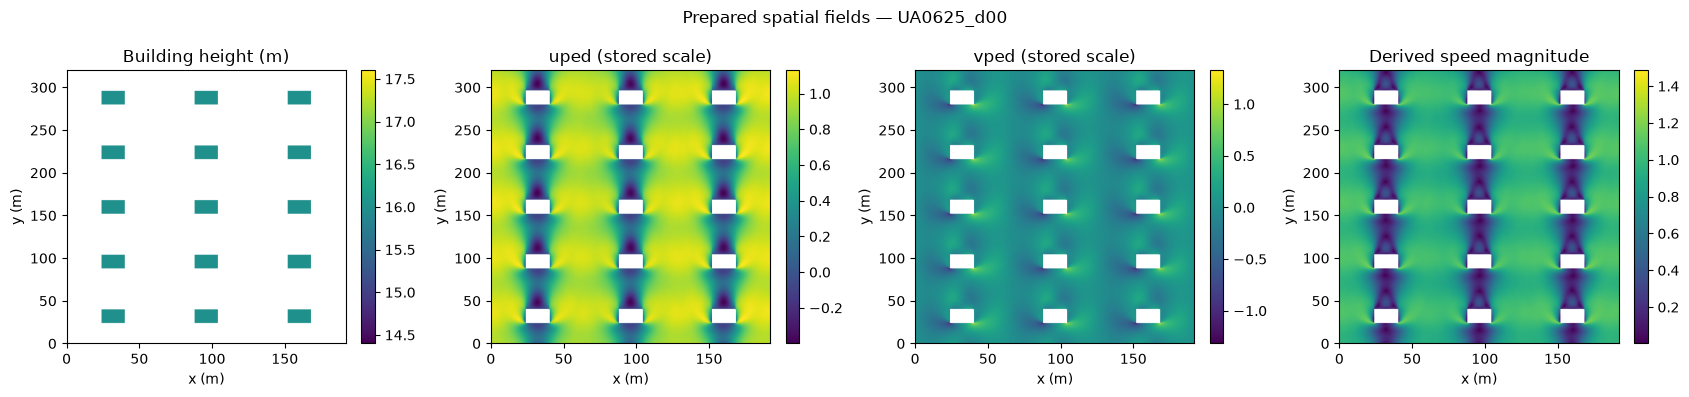

All DL_01 runtime outputs are under: /Users/suhaanigarg/Desktop/T006-urban-microclimate-modelling/dl_results


In [10]:
sample_case = manifest.iloc[0]["simulation_id"]
with np.load(FIELDS_DIR / f"{sample_case}.npz") as sample:
    height_map = sample["height_map"]
    u_field = sample["u"]
    v_field = sample["v"]
    valid_mask = sample["valid_mask"].astype(bool)
    x_m = sample["x_m"]
    y_m = sample["y_m"]

speed_field = np.sqrt(u_field ** 2 + v_field ** 2)
fig, axes = plt.subplots(1, 4, figsize=(17, 4))
plots = [
    (np.ma.masked_where(height_map <= 0, height_map), "Building height (m)"),
    (np.ma.masked_where(~valid_mask, u_field), "uped (stored scale)"),
    (np.ma.masked_where(~valid_mask, v_field), "vped (stored scale)"),
    (np.ma.masked_where(~valid_mask, speed_field), "Derived speed magnitude"),
]
extent = [float(x_m.min()), float(x_m.max()), float(y_m.min()), float(y_m.max())]
for axis, (array, title) in zip(axes, plots):
    image = axis.imshow(array, origin="lower", extent=extent, aspect="auto")
    axis.set_title(title)
    axis.set_xlabel("x (m)")
    axis.set_ylabel("y (m)")
    fig.colorbar(image, ax=axis, fraction=0.046)
fig.suptitle(f"Prepared spatial fields — {sample_case}")
fig.tight_layout()
fig.savefig(FIGURES_DIR / f"{sample_case}_prepared_data_check.png", dpi=160)
plt.show()
plt.close(fig)

print("All DL_01 runtime outputs are under:", DL_RESULTS)

## DL_01 completion checklist

- [ ] The full archive passed its ZIP integrity check.
- [ ] 224 metadata cases were matched to 224 `*_ped.nc` and 224 `_topo` files.
- [ ] All spatial shapes were checked before alignment.
- [ ] The original resolution and coordinates were retained.
- [ ] The valid-air mask excludes buildings and non-finite targets.
- [ ] The family-held-out split has no family or layout overlap.
- [ ] Normalization statistics were fitted on training cases only.
- [ ] All data-audit files and diagnostic plots were generated under `dl_results/`.

**Handoff:** Aarya uses the prepared data schema and split manifest in DL_02; Palak uses them for training in DL_03.